# S3 · Classroom relational structure

Each classroom is a small closed group in which we observe several
networks at once. This notebook describes the three nomination networks
used in the analysis and draws them for a few classrooms. Code:
`code/si/S3_relational_structure.R`.

In [ ]:
here::i_am("notebooks/si/S3_relational_structure.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
source(here("code", "si", "figures", "S3_figures.R"))   # plotting functions of this section
library(igraph)
library(ggraph)
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE)
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)

question_names <- c(
  nom_q1 = "Most like to hang out (Q1)",  nom_q2 = "Least like to hang out (Q2)",
  nom_q3 = "Best friends (Q3)",            nom_q4 = "Most popular (Q4)",
  nom_q5 = "Not popular (Q5)",             nom_q6 = "Start fights (Q6)",
  nom_q7 = "Make fun of others (Q7)",      nom_q8 = "Kind to others (Q8)",
  nom_q9 = "Cooperate (Q9)"
)

## Network statistics, classroom by classroom (Table S6)

For each classroom and question: number of ties, density, nominations
received, reciprocity (share of ties that are returned) and isolates.

In [ ]:
# For one classroom and one question, the directed nomination network and
# its statistics. Ties are nominations i -> j; "no tie" is an observed
# non-nomination, not missing data.

network_statistics <- function(this_class, question) {
  class_dyads <- dyads %>% filter(class_id == this_class)
  n_children <- n_distinct(class_dyads$sender_id)
  nominations <- class_dyads %>% filter(.data[[question]] == 1)

  received <- class_dyads %>% group_by(id = receiver_id) %>% summarise(k_in = sum(.data[[question]]))
  sent     <- class_dyads %>% group_by(id = sender_id)   %>% summarise(k_out = sum(.data[[question]]))
  degrees  <- full_join(received, sent, by = "id")

  # reciprocity: share of ties whose reverse tie also exists
  reciprocated <- nominations %>%
    semi_join(nominations, by = c("sender_id" = "receiver_id", "receiver_id" = "sender_id"))

  tibble(class_id      = this_class,
         question      = question,
         n             = n_children,
         ties          = nrow(nominations),
         density       = nrow(nominations) / (n_children * (n_children - 1)),
         mean_received = mean(degrees$k_in),
         min_received  = min(degrees$k_in),
         max_received  = max(degrees$k_in),
         zero_received = sum(degrees$k_in == 0),
         reciprocity   = nrow(reciprocated) / nrow(nominations),
         isolates      = sum(degrees$k_in == 0 & degrees$k_out == 0))
}

table_s6 <- expand_grid(this_class = sort(unique(dyads$class_id)),
                        question   = c("nom_q3", "nom_q4", "nom_q5")) %>%
  pmap_dfr(network_statistics) %>%
  left_join(students %>% distinct(class_id, school_id), by = "class_id") %>%
  mutate(network = question_names[question], .after = n)

table_s6 %>% filter(class_id == 1)

class_id,question,n,network,ties,density,mean_received,min_received,max_received,zero_received,reciprocity,isolates,school_id
1,nom_q3,33,Best friends (Q3),114,0.1079545,3.454546,0,9,1,0.4736842,0,1
1,nom_q4,33,Most popular (Q4),98,0.0928030,2.969697,0,16,6,0.1632653,0,1
1,nom_q5,33,Not popular (Q5),78,0.0738636,2.363636,0,14,6,0.0769231,0,1


## Table S5. Summary over the 45 classrooms

Median and range of each statistic across classrooms.

In [ ]:
# Table S5: median and range over the 45 classrooms
median_range <- function(x, digits = 2) {
  paste0(format(round(median(x), digits), nsmall = digits),
         " [", format(round(min(x), digits), nsmall = digits), "-",
         format(round(max(x), digits), nsmall = digits), "]")
}

table_s5 <- table_s6 %>%
  group_by(network) %>%
  summarise(`Classroom size`             = median_range(n, 0),
            `Directed ties`              = median_range(ties, 0),
            Density                      = median_range(density),
            `Mean nominations received`  = median_range(mean_received),
            `Max nominations received`   = median_range(max_received, 0),
            Reciprocity                  = median_range(reciprocity),
            `Students with zero received` = median_range(zero_received, 0),
            Isolates                     = median_range(isolates, 0)) %>%
  pivot_longer(-network, names_to = "statistic") %>%
  pivot_wider(names_from = network, values_from = value)

In [ ]:
knitr::kable(table_s5)

statistic,Best friends (Q3),Most popular (Q4),Not popular (Q5)
Classroom size,18 [7-39],18 [7-39],18 [7-39]
Directed ties,52 [15-145],46 [12-130],41 [6-104]
Density,0.17 [0.10-0.36],0.14 [0.09-0.35],0.12 [0.07-0.29]
Mean nominations received,3.00 [1.87-4.00],2.52 [1.21-3.83],2.17 [0.60-3.09]
Max nominations received,8 [3-12],10 [3-22],7 [3-14]
Reciprocity,0.51 [0.32-0.70],0.21 [0.00-0.67],0.12 [0.00-0.50]
Students with zero received,2 [0-5],4 [1-12],3 [0-9]
Isolates,0 [0-2],0 [0-1],0 [0-4]


## Sociograms

The same layout is used for every layer of a classroom, so each child
keeps her position. Node size is nominations received (or tokens), and
the subtitle gives the share of ties between children of the same sex.

In [ ]:
# One sociogram: one classroom, one layer. Node size = nominations received
# (or tokens received/sent), fill = sex. The layout is fixed per classroom
# so the same child stays in the same place in every panel.

class_layout <- function(this_class, seed = 1) {
  class_dyads <- dyads %>% filter(class_id == this_class)
  links <- class_dyads %>%
    filter(nom_q3 == 1 | nom_q4 == 1 | nom_q5 == 1) %>%
    transmute(from = as.character(sender_id), to = as.character(receiver_id))
  nodes <- students %>% filter(class_id == this_class) %>%
    transmute(name = as.character(student_id), sex = factor(if_else(female == 1, "Female", "Male"), levels = c("Female", "Male")))
  set.seed(seed)
  xy <- layout_with_fr(graph_from_data_frame(links, vertices = nodes))
  nodes %>% mutate(x = xy[, 1], y = xy[, 2])
}

draw_sociogram <- function(this_class, layer, nodes, title = layer) {
  class_dyads <- dyads %>% filter(class_id == this_class) %>%
    mutate(from = as.character(sender_id), to = as.character(receiver_id))

  if (layer %in% c("tokens_sent", "tokens_received")) {
    links <- class_dyads %>% filter(tokens_sent > 0) %>% mutate(width = tokens_sent)
    size  <- class_dyads %>%
      group_by(name = if (layer == "tokens_sent") from else to) %>%
      summarise(size = sum(tokens_sent))
  } else {
    links <- class_dyads %>% filter(.data[[layer]] == 1) %>% mutate(width = 1)
    size  <- class_dyads %>% group_by(name = to) %>% summarise(size = sum(.data[[layer]]))
  }

  # share of ties between two children of the same sex
  sex_of <- setNames(nodes$sex, nodes$name)
  same_sex <- 100 * mean(sex_of[links$from] == sex_of[links$to])

  nodes <- nodes %>% left_join(size, by = "name")
  network <- graph_from_data_frame(links %>% select(from, to, width), vertices = nodes)

  ggraph(network, layout = "manual", x = V(network)$x, y = V(network)$y) +
    geom_edge_link(aes(width = width), color = "grey45", alpha = 0.6,
                   arrow = arrow(length = unit(1.5, "mm"), type = "closed"),
                   end_cap = circle(2.5, "mm")) +
    geom_node_point(aes(size = size, fill = sex), shape = 21, color = "grey20") +
    scale_edge_width(range = c(0.2, 1)) +
    scale_fill_manual(values = c(Female = color_female, Male = color_male)) +
    scale_size_continuous(range = c(1.5, 7)) +
    labs(title = title, subtitle = sprintf("%.0f%% same-sex ties", same_sex)) +
    theme_void(base_size = 8) +
    theme(legend.position = "none", plot.title = element_text(face = "bold"))
}

### Figure S2. All layers of classroom 20

Each panel is one network of the same classroom, with every child in the
same position.

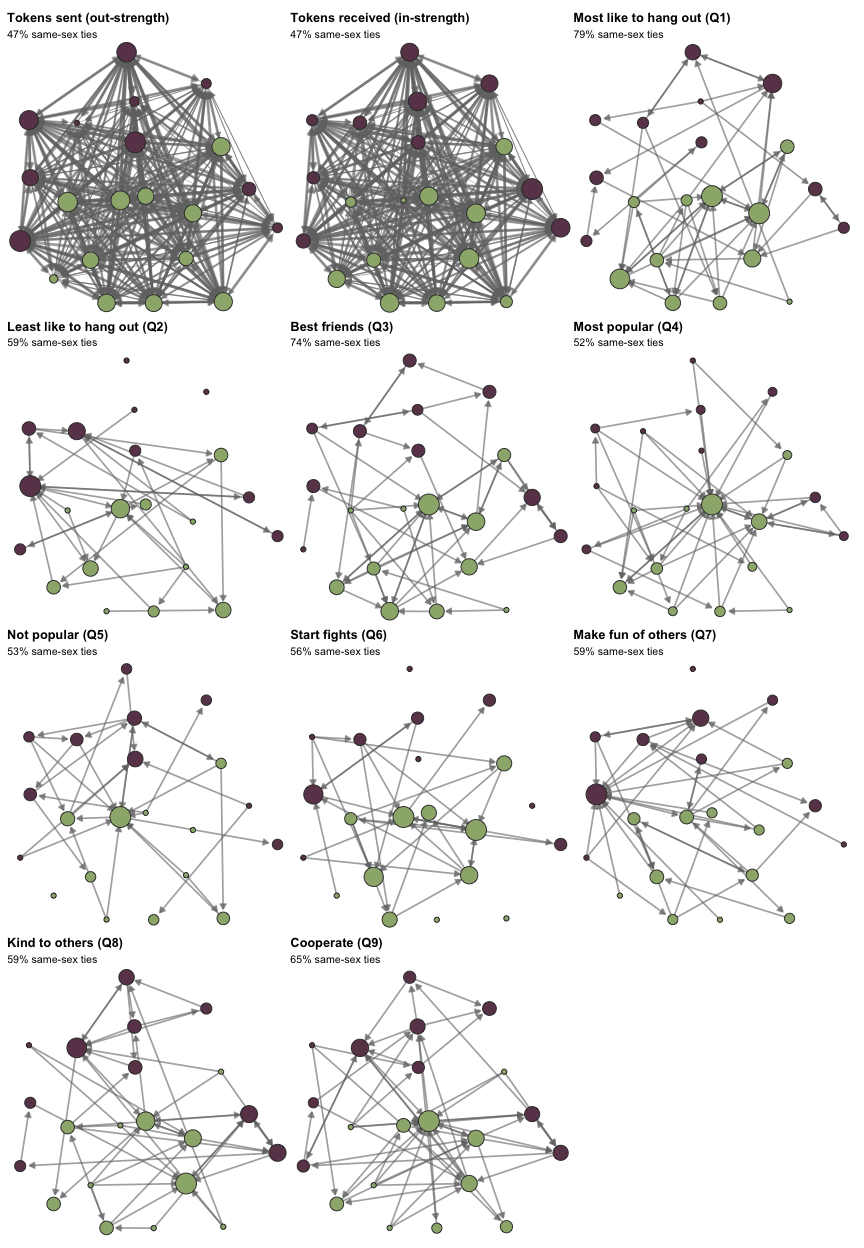

In [ ]:
# Figure S2, minimal version: every layer of class 20 as a grid of sociograms
# (same positions in every panel)
nodes_20 <- class_layout(20, seed = 20)
layers <- c("tokens_sent", "tokens_received", names(question_names))
layer_titles <- c("Tokens sent (out-strength)", "Tokens received (in-strength)", question_names)

figure_s2_minimal <- map2(layers, layer_titles, ~ draw_sociogram(20, .x, nodes_20, .y)) %>%
  wrap_plots(ncol = 3)

figure_s2_minimal

#### Supporting Information layout

The same layers drawn as tilted planes stacked from top to bottom and
grouped by kind. This is the version saved to `output/figures/si/`.

In [ ]:
# Figure S2 as in the SI: the layers of one classroom drawn as flat planes,
# stacked from top to bottom like a staircase and grouped by kind (game, friendship, positive
# and negative nominations). Each child keeps the same position in every plane.
plot_figure_s2 <- function(dyads, nodes_20) {
  nodes_20 <- nodes_20 %>%
    mutate(x = scales::rescale(x, to = c(-1, 1)), y = scales::rescale(y, to = c(-1, 1)))

  layer_info <- tribble(
    ~layer,            ~label,                          ~group,
    "tokens_sent",     "Tokens sent\nout-strength",     "Cooperation game",
    "tokens_received", "Tokens received\nin-strength",  "Cooperation game",
    "nom_q3",          "Q3  Best friends",              "Friendship",
    "nom_q1",          "Q1  Most like to hang out",     "Positive nominations",
    "nom_q4",          "Q4  Most popular and well-known", "Positive nominations",
    "nom_q8",          "Q8  Kind",                      "Positive nominations",
    "nom_q9",          "Q9  Cooperates",                "Positive nominations",
    "nom_q5",          "Q5  Not popular or well-known", "Negative nominations",
    "nom_q2",          "Q2  Least like to hang out",    "Negative nominations",
    "nom_q7",          "Q7  Makes fun of others",       "Negative nominations",
    "nom_q6",          "Q6  Starts fights",             "Negative nominations"
  ) %>%
    mutate(row    = row_number(),
           center = -0.92 * (row - 1),       # vertical position of each plane
           shift  = -0.09 * (row - 1),       # each plane a little to the left
           color  = c(`Cooperation game` = "grey25", Friendship = color_mutual,
                      `Positive nominations` = "#1F3A5F", `Negative nominations` = color_highlight)[group])

  tilt_plane <- function(x, y, center, shift) {
    tibble(X = 1.6 * x + shift, Y = 0.34 * y + center)
  }

  class20 <- dyads %>% filter(class_id == 20) %>%
    mutate(from = as.character(sender_id), to = as.character(receiver_id))
  sex_of <- setNames(nodes_20$sex, nodes_20$name)

  # links of every layer (tokens: every transfer of at least one token)
  layer_links <- map_dfr(layer_info$layer, function(this_layer) {
    links <- if (str_starts(this_layer, "tokens")) filter(class20, tokens_sent > 0)
             else filter(class20, .data[[this_layer]] == 1)
    links %>% transmute(layer = this_layer, from, to,
                        mutual = paste(to, from) %in% paste(from, to),
                        weight = if (str_starts(this_layer, "tokens")) tokens_sent else 1)
  })

  # node size: tokens or nominations received (tokens sent for the first plane)
  layer_sizes <- map_dfr(layer_info$layer, function(this_layer) {
    if (this_layer == "tokens_sent") {
      class20 %>% group_by(name = from) %>% summarise(value = sum(tokens_sent))
    } else if (this_layer == "tokens_received") {
      class20 %>% group_by(name = to) %>% summarise(value = sum(tokens_sent))
    } else {
      class20 %>% group_by(name = to) %>% summarise(value = sum(.data[[this_layer]]))
    }
  } %>% mutate(layer = this_layer, size = 0.5 + 3 * sqrt(value / max(value))))

  # share of same-sex ties (for tokens, weighted by the number of tokens)
  same_sex <- layer_links %>%
    group_by(layer) %>%
    summarise(same_sex = round(100 * weighted.mean(sex_of[from] == sex_of[to], weight)))

  plane_frames <- layer_info %>%
    rowwise() %>%
    reframe(layer, color, tilt_plane(c(-1.15, 1.15, 1.15, -1.15), c(-1.33, -1.33, 1.33, 1.33), center, shift))

  plane_nodes <- layer_sizes %>%
    left_join(nodes_20, by = "name") %>%
    left_join(layer_info, by = "layer") %>%
    mutate(tilt_plane(x, y, center, shift))

  plane_links <- layer_links %>%
    left_join(nodes_20 %>% select(from = name, x0 = x, y0 = y), by = "from") %>%
    left_join(nodes_20 %>% select(to = name, x1 = x, y1 = y), by = "to") %>%
    left_join(layer_info, by = "layer") %>%
    mutate(tilt_plane(x0, y0, center, shift) %>% rename(X0 = X, Y0 = Y),
           tilt_plane(x1, y1, center, shift) %>% rename(X1 = X, Y1 = Y),
           # friendship: mutual ties in green, one-way ties light
           link_color = case_when(layer == "nom_q3" & mutual ~ color_mutual,
                                  layer == "nom_q3"           ~ "#9FCFC8",
                                  TRUE                        ~ "grey55"),
           tie = if_else(mutual, "Mutual", "Unilateral"))

  plane_labels <- layer_info %>%
    left_join(same_sex, by = "layer") %>%
    mutate(text = paste0(label, if_else(str_starts(layer, "tokens"), " | ", "\n"),
                         same_sex, "% same-sex"),
           X = 1.6 * 1.15 + shift + 0.12)

  group_brackets <- layer_info %>%
    group_by(group, color) %>%
    summarise(top = max(center) + 0.5, bottom = min(center) - 0.5, .groups = "drop") %>%
    mutate(X = -2.95)

  figure_s2 <- ggplot() +
    geom_polygon(data = plane_frames, aes(X, Y, group = layer, color = I(color),
                                          fill = I(alpha(color, 0.03))), linewidth = 0.5) +
    geom_segment(data = filter(plane_links, layer != "nom_q3"),
                 aes(x = X0, y = Y0, xend = X1, yend = Y1, color = I(link_color)),
                 linewidth = 0.15, alpha = 0.7,
                 arrow = arrow(length = unit(0.6, "mm"), type = "closed")) +
    geom_segment(data = filter(plane_links, layer == "nom_q3"),
                 aes(x = X0, y = Y0, xend = X1, yend = Y1, color = I(link_color), linetype = tie),
                 linewidth = 0.35, arrow = arrow(length = unit(0.6, "mm"), type = "closed")) +
    geom_point(data = plane_nodes, aes(X, Y, size = I(size), fill = sex),
               shape = 21, color = "grey20", stroke = 0.15) +
    geom_text(data = plane_labels, aes(X, center, label = text, color = I(color)),
              hjust = 0, size = 2.1, lineheight = 0.9) +
    geom_segment(data = group_brackets, aes(x = X, xend = X, y = bottom, yend = top, color = I(color)),
                 linewidth = 0.6) +
    geom_segment(data = group_brackets, aes(x = X, xend = X + 0.12, y = top, yend = top, color = I(color)),
                 linewidth = 0.6) +
    geom_segment(data = group_brackets, aes(x = X, xend = X + 0.12, y = bottom, yend = bottom, color = I(color)),
                 linewidth = 0.6) +
    geom_text(data = group_brackets, aes(X - 0.12, (top + bottom) / 2, label = group, color = I(color)),
              angle = 90, fontface = "bold", size = 2.4) +
    scale_fill_manual(values = c(Female = color_female, Male = color_male), name = NULL) +
    scale_linetype_manual(values = c(Mutual = "solid", Unilateral = "solid"), name = "Friendship tie") +
    guides(fill = guide_legend(order = 1, override.aes = list(size = 3)),
           linetype = guide_legend(order = 2, override.aes = list(color = c(color_mutual, "#9FCFC8"),
                                                                  linewidth = 0.8))) +
    coord_fixed(clip = "off", xlim = c(-3.1, 4.3)) +
    labs(title = "Relational layers in one classroom") +
    theme_void(base_size = 9) +
    theme(plot.title = element_text(face = "bold"), legend.position = "top",
          plot.background = element_rect(fill = "white", color = NA),
          legend.text = element_text(size = 7), legend.title = element_text(size = 7))
  figure_s2
}

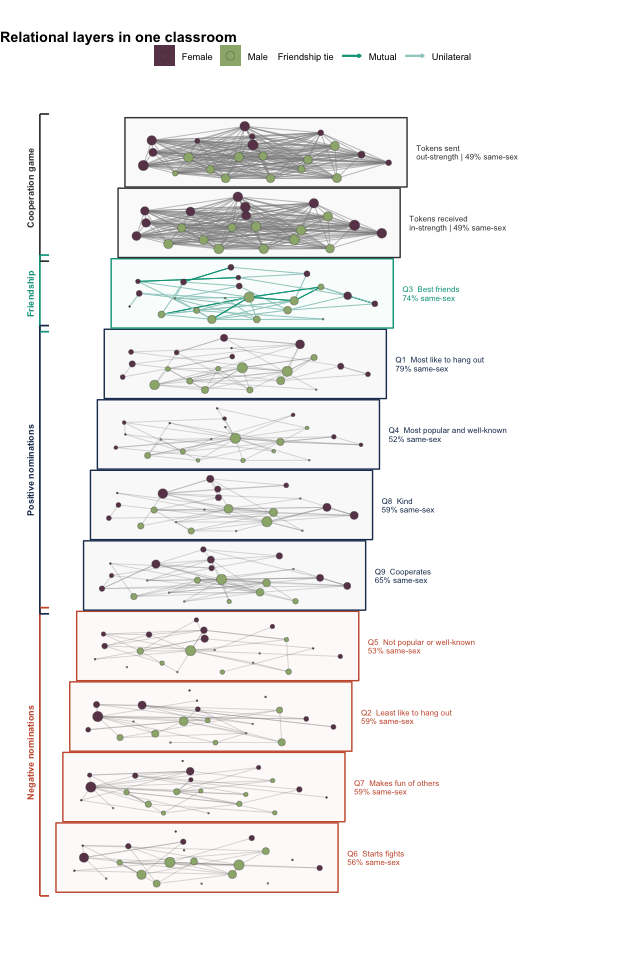

In [ ]:
# Figure S2 as in the SI: the same layers drawn as tilted planes stacked from
# top to bottom and grouped by kind: the game (tokens), friendship, positive
# and negative nominations. Each child keeps the same position in every plane.
figure_s2 <- plot_figure_s2(dyads, nodes_20)
figure_s2

### Figures S3–S5. Small, intermediate and large classrooms

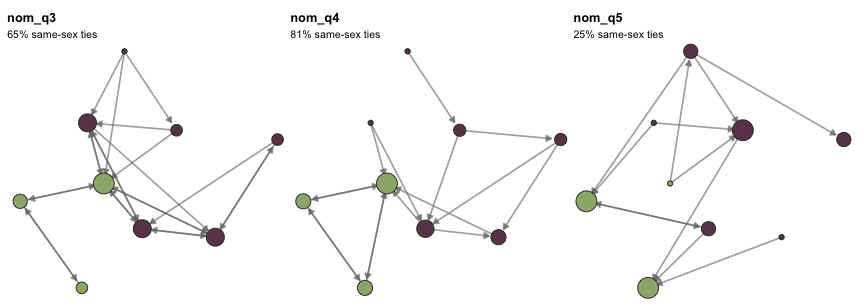

In [ ]:
# Figures S3-S5: the three focal questions for three classroom sizes.
# Gray arrows are nominations; a reciprocated pair is drawn once, curved,
# with a head at each end. Node size = nominations received in that network.
# Quick look: the three focal networks of the small classroom
nodes_16 <- class_layout(16, seed = 16)
map(c("nom_q3", "nom_q4", "nom_q5"), ~ draw_sociogram(16, .x, nodes_16)) %>%
  wrap_plots(nrow = 1)

#### Supporting Information layout

Plotting code from `code/si/figures/S3_figures.R`. This is the version
saved to `output/figures/si/`.

In [ ]:
focal <- c(nom_q3 = "Best friends (Q3)",
           nom_q4 = "Most popular and well-known (Q4)",
           nom_q5 = "Not popular or well-known (Q5)")

draw_focal_layer <- function(dyads, this_class, question, nodes, title, max_size) {
  class_dyads <- dyads %>% filter(class_id == this_class) %>%
    mutate(from = as.character(sender_id), to = as.character(receiver_id))
  links <- class_dyads %>% filter(.data[[question]] == 1) %>% select(from, to)

  # reciprocated pairs: keep one row per pair and mark it
  links <- links %>%
    mutate(mutual = paste(to, from) %in% paste(from, to)) %>%
    filter(!mutual | from < to)

  received <- class_dyads %>% group_by(name = to) %>% summarise(received = sum(.data[[question]]))
  sent     <- class_dyads %>% group_by(name = from) %>% summarise(sent = sum(.data[[question]]))
  nodes <- nodes %>% left_join(received, by = "name") %>% left_join(sent, by = "name")
  isolates <- sum(nodes$received == 0 & nodes$sent == 0)
  ties <- sum(class_dyads[[question]])

  network <- graph_from_data_frame(links, vertices = nodes)
  arrow_head <- function(ends) arrow(length = unit(1.4, "mm"), type = "closed", ends = ends)

  ggraph(network, layout = "manual", x = V(network)$x, y = V(network)$y) +
    geom_edge_link(aes(filter = !mutual), color = "grey50",
                   arrow = arrow_head("last"), end_cap = circle(2.6, "mm"), width = 0.35) +
    geom_edge_arc(aes(filter = mutual), strength = 0.25, color = "grey50",
                  arrow = arrow_head("both"), start_cap = circle(2.6, "mm"),
                  end_cap = circle(2.6, "mm"), width = 0.35) +
    geom_node_point(aes(size = received, fill = sex), shape = 21, color = "grey20", stroke = 0.3) +
    scale_fill_manual(values = c(Female = color_female, Male = color_male), name = NULL,
                      drop = FALSE) +
    scale_size(range = c(1.2, 9), limits = c(0, max_size), name = "Nominations received",
               breaks = unique(c(pretty(c(0, max_size), n = 4), max_size))) +
    labs(title = paste0(title, "\n", ties, " ties, ", isolates, " isolates")) +
    theme_void(base_size = 8) +
    theme(plot.title = element_text(face = "bold", hjust = 0.5, size = 8, color = color_text))
}

plot_focal_layers <- function(dyads, nodes, this_class) {
  # one size scale for the three panels: the largest number received
  max_received <- dyads %>% filter(class_id == this_class) %>%
    group_by(receiver_id) %>%
    summarise(across(c(nom_q3, nom_q4, nom_q5), sum)) %>%
    select(-receiver_id) %>% max()
  map2(names(focal), focal, ~ draw_focal_layer(dyads, this_class, .x, nodes, .y, max_received)) %>%
    wrap_plots(nrow = 1, guides = "collect") &
    theme(legend.position = "bottom") &
    guides(size = guide_legend(nrow = 1, override.aes = list(fill = "white")),
           fill = guide_legend(override.aes = list(size = 3)))
}

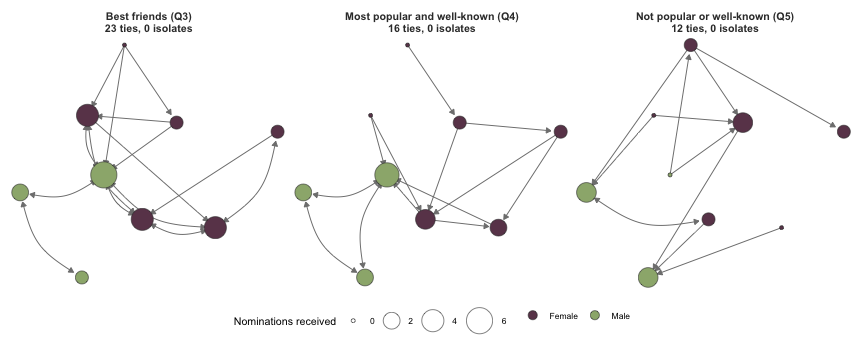

In [ ]:
# Supporting Information layout (plotting code in figures/S3_figures.R)
figure_s3 <- plot_focal_layers(dyads, class_layout(16, seed = 16), 16)   # small, 9 children
figure_s4 <- plot_focal_layers(dyads, class_layout(40, seed = 40), 40)   # intermediate, 18 children (all girls)
figure_s5 <- plot_focal_layers(dyads, class_layout(1, seed = 1), 1)      # large, 33 children

figure_s3

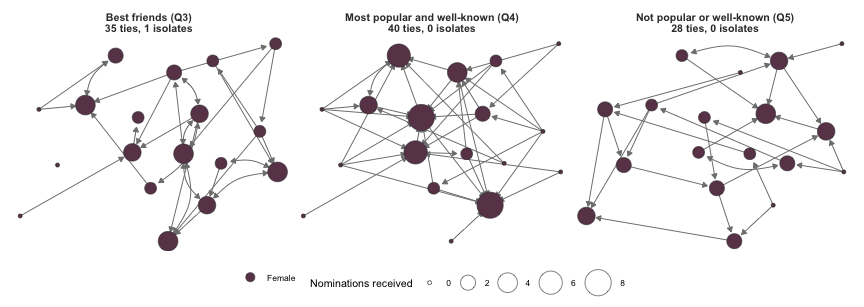

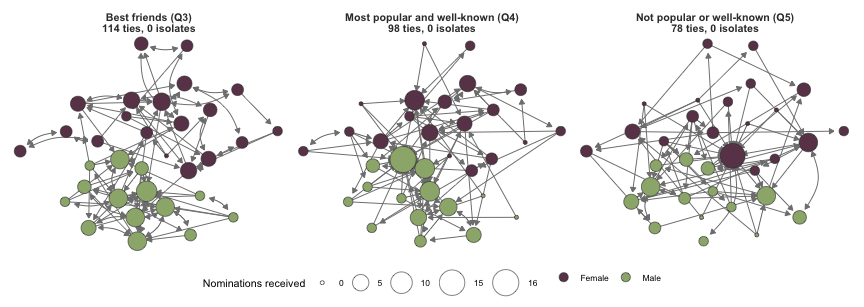

In [ ]:
figure_s4

In [ ]:
save_table(table_s5, "S3_table_s5_network_summary")
save_table(table_s6, "S3_table_s6_network_by_class")
save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}
save_si_figure(figure_s2, "S3_figure_s2_class20_layers", 6.5, 10)
save_si_figure(figure_s3, "S3_figure_s3_class16", 9, 3.6)
save_si_figure(figure_s4, "S3_figure_s4_class40", 9, 3.6)
save_si_figure(figure_s5, "S3_figure_s5_class1", 9, 3.6)